# 09 · Full photos, strategy 3: find the head with body keypoints

Notebook 07 cropped the head with a fixed rule over the person box. Here we find the head with **body keypoints** detected by a model: points such as the nose, eyes, ears and shoulders.

```
Photo → Keypoint R-CNN → for each person: box + 17 keypoints (nose, eyes, ears, shoulders, …)
      → head box computed from nose / eyes / ears / shoulders → 224×224
      → helmet_and_color.keras (the same model as notebook 07, unchanged) → decision
```

## Step 1 · Keypoint R-CNN (torchvision, BSD-3 license)
- `keypointrcnn_resnet50_fpn` with `COCO_V1` weights, 59 million weights. We do not train it. It replaces YOLOX here: it finds the persons and their 17 keypoints.
- It runs on the Mac GPU (MPS), an NVIDIA GPU (CUDA) or the CPU.
- A person is accepted if its score is ≥ 0.5. A keypoint is visible if its score (logit) is > 2.
- Keypoints used: 0 nose, 1–2 eyes, 3–4 ears, 5–6 shoulders.

## Step 2 · Head box from the keypoints
**Head width a:** the largest of the available estimates (in a side view the distance between the eyes or the ears shrinks; taking the largest protects against that):
- 1.0 × ear-to-ear distance
- 2.5 × eye-to-eye distance (about 6 cm between pupils, about 15 cm of head)
- 0.45 × shoulder-to-shoulder distance (about 40 cm of shoulders, about 18 cm of head)

**Center:** the mean (x̄, ȳ) of the visible face keypoints, roughly at eye height.
- A head with a helmet goes from ~1.0·a above the eyes (top of the helmet) to ~0.6·a below (chin). Its center is at ȳ − 0.2·a and it is ~1.6·a tall.
- With the same 1.3× margin used to train output A: **L = 1.3 × 1.6·a ≈ 2.0·a**.
- **Crop:** square of side L centered at (x̄, ȳ − 0.2·a).

**If no face keypoint is visible** (person seen from behind): center at the middle of the shoulders, 1.1·a higher.
**If the shoulders are not visible either:** the fixed rule of notebook 07.

## Steps 3 and 4 · Same as notebook 07
Same two-output model, same 0.5 threshold, same evaluation.

In [1]:
import xml.etree.ElementTree as ET
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import keras
from PIL import Image, ImageOps, ImageDraw, ImageFilter, ImageFont
from torchvision.models.detection import keypointrcnn_resnet50_fpn, KeypointRCNN_ResNet50_FPN_Weights
from torchvision.transforms.functional import to_tensor

REPO = Path.cwd().parent
SHWD = REPO / "data/VOC2028"
OUTPUTS, MODELS = REPO / "outputs", REPO / "models"
COLORS = ["green", "orange", "red", "transparent", "yellow"]
PERSON_THRESHOLD, VISIBLE_POINT, HELMET_THRESHOLD, MIN_SIDE = 0.5, 2.0, 0.5, 32

DEVICE = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
kprcnn = keypointrcnn_resnet50_fpn(weights=KeypointRCNN_ResNet50_FPN_Weights.COCO_V1).eval().to(DEVICE)
model = keras.models.load_model(MODELS / "helmet_and_color.keras")
print(DEVICE)

mps


## 1. Functions

In [2]:
FACE, SHOULDERS = [0, 1, 2, 3, 4], [5, 6]

def head_box(box, kp, visible):
    # Step 2. kp: 17×2 keypoints; visible: 17 booleans. Returns (box, source of the head width)
    dist = lambda i, j: np.linalg.norm(kp[i] - kp[j]) if visible[i] and visible[j] else 0.0
    estimates = {"ears": 1.0 * dist(3, 4), "eyes": 2.5 * dist(1, 2), "shoulders": 0.45 * dist(5, 6)}
    a = max(estimates.values())
    face = [i for i in FACE if visible[i]]
    if a > 0 and face:
        cx, cy = kp[face].mean(0)
        cy -= 0.2 * a
        source = max(estimates, key=estimates.get)
    elif a > 0 and all(visible[SHOULDERS]):
        cx, cy = kp[SHOULDERS].mean(0)
        cy -= 1.1 * a
        source = "shoulders (from behind)"
    else:                                                     # fixed rule of notebook 07
        x1, y1, x2, y2 = box
        h = y2 - y1
        return np.array([(x1 + x2) / 2 - 0.175 * h, y1 - 0.10 * h, (x1 + x2) / 2 + 0.175 * h, y1 + 0.25 * h]), "fixed rule"
    L = 2.0 * a
    return np.array([cx - L / 2, cy - L / 2, cx + L / 2, cy + L / 2]), source

def analyze(img):
    with torch.no_grad():
        o = kprcnn([to_tensor(img).to(DEVICE)])[0]
    k = (o["scores"] >= PERSON_THRESHOLD).cpu().numpy()
    if not k.any():
        return pd.DataFrame()
    boxes, kps = o["boxes"].cpu().numpy()[k], o["keypoints"].cpu().numpy()[k][..., :2]
    vis = o["keypoints_scores"].cpu().numpy()[k] > VISIBLE_POINT
    hb = [head_box(b, p, v) for b, p, v in zip(boxes, kps, vis)]
    heads = np.stack([b for b, _ in hb])
    X = np.stack([np.asarray(img.crop(tuple(c)).resize((224, 224), Image.BILINEAR)) for c in heads]).astype("float32")
    out = model.predict(X, verbose=0)
    p_helmet = out["helmet"].ravel()
    return pd.DataFrame({"head_rect": list(heads), "source": [s for _, s in hb], "p_helmet": p_helmet,
                         "helmet": p_helmet >= HELMET_THRESHOLD, "color": np.array(COLORS)[out["color"].argmax(1)],
                         "kp": list(kps), "vis": list(vis)})

def draw(img, res):
    # Blur the face (lower half of the head crop), draw the head box and its label
    img = img.copy(); d = ImageDraw.Draw(img)
    font = ImageFont.load_default(size=max(14, img.width // 45))     # readable on large photos
    width = max(3, img.width // 300)
    for _, r in res.iterrows():
        x1, y1, x2, y2 = r.head_rect
        face = tuple(int(v) for v in (x1, (y1 + y2) / 2, x2, y2))
        if face[2] > face[0] and face[3] > face[1]:
            img.paste(img.crop(face).filter(ImageFilter.GaussianBlur(float(max(2, (x2 - x1) / 10)))), face[:2])
        label, col = (f"HELMET {r.color}", "lime") if r.helmet else ("NO HELMET", "red")
        d.rectangle(tuple(r.head_rect), outline=col, width=width)
        text = f"{label} {r.p_helmet:.2f}"
        tb = d.textbbox((x1, max(0, y1 - font.size - 4)), text, font=font)
        d.rectangle(tb, fill="black")                                   # dark background so the text is readable
        d.text(tb[:2], text, fill=col, font=font)
    return img

## 2. Evaluation on the test photos (same as notebook 07)

In [3]:
test_ids = (SHWD / "ImageSets/Main/test.txt").read_text().split()
rows, sources = [], []
for img_id in test_ids:
    root = ET.parse(SHWD / f"Annotations/{img_id}.xml").getroot()
    labeled = [(o.findtext("name"), [int(float(o.find("bndbox").findtext(t))) for t in ("xmin", "ymin", "xmax", "ymax")])
               for o in root.iter("object") if o.findtext("name") in ("hat", "person")]
    labeled = [(c, b) for c, b in labeled if min(b[2] - b[0], b[3] - b[1]) >= MIN_SIDE]
    if not labeled:
        continue
    img = ImageOps.exif_transpose(Image.open(SHWD / f"JPEGImages/{img_id}.jpg")).convert("RGB")
    res = analyze(img)
    sources += list(res.source) if len(res) else []
    kind = "with some helmet" if any(c == "hat" for c, _ in labeled) else "no helmet only"
    for label, b in labeled:
        b = np.array(b, float)
        fraction, decision = 0.0, None
        if len(res):
            C = np.stack(res.head_rect)
            inter = (np.clip(np.minimum(C[:, 2], b[2]) - np.maximum(C[:, 0], b[0]), 0, None) *
                     np.clip(np.minimum(C[:, 3], b[3]) - np.maximum(C[:, 1], b[1]), 0, None))
            f = inter / ((b[2] - b[0]) * (b[3] - b[1]))
            j = f.argmax(); fraction, decision = f[j], bool(res.helmet.iloc[j])
        rows.append({"id": img_id, "kind": kind, "true_helmet": label == "hat",
                     "covered_fraction": fraction, "covered": fraction >= 0.9, "pred_helmet": decision})
ev = pd.DataFrame(rows)

ev.to_csv(OUTPUTS / "09_test_evaluation.csv", index=False)
print(len(ev), "heads in", ev.id.nunique(), "photos")
print("Where the head width came from (all detected persons):")
pd.Series(sources).value_counts(normalize=True).round(3)

6716 heads in 1343 photos
Where the head width came from (all detected persons):


ears                       0.574
eyes                       0.283
shoulders                  0.105
fixed rule                 0.037
shoulders (from behind)    0.002
Name: proportion, dtype: float64

In [4]:
def metrics(true, covered, pred):
    true, cov = np.asarray(true, bool), np.asarray(covered, bool)
    pred_cov = np.asarray(pred, dtype=object)[cov].astype(bool)      # pred is None/NaN where nothing covers the head
    correct = np.zeros(len(true), bool)
    correct[cov] = pred_cov == true[cov]
    return {"coverage": cov.mean(),
            "sensitivity no helmet": (~pred_cov[~true[cov]]).mean() if (~true[cov]).any() else np.nan,
            "specificity helmet": pred_cov[true[cov]].mean() if true[cov].any() else np.nan,
            "end to end": correct.mean()}

comparison = pd.read_csv(OUTPUTS / "08_comparison.csv", index_col=0)
comparison.loc["body keypoints (09)"] = metrics(ev.true_helmet, ev.covered, ev.pred_helmet)
comparison.to_csv(OUTPUTS / "09_comparison.csv")
comparison.round(3)

,coverage,sensitivity no helmet,specificity helmet,end to end
fixed rule (07),0.168,0.935,0.993,0.161
"whole person, output A as is",0.729,0.893,0.997,0.667
"whole person, output A' retrained",0.729,0.987,0.976,0.717
body keypoints (09),0.684,0.979,0.993,0.671


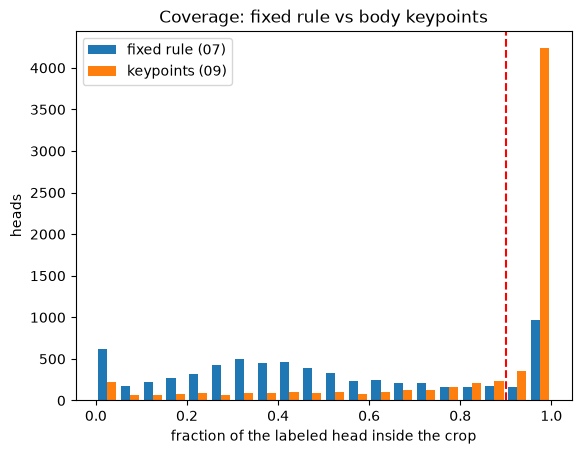

In [5]:
ev07 = pd.read_csv(OUTPUTS / "07_test_evaluation.csv")
plt.hist([ev07.covered_fraction, ev.covered_fraction], bins=20, label=["fixed rule (07)", "keypoints (09)"])
plt.axvline(0.9, c="red", ls="--"); plt.legend()
plt.xlabel("fraction of the labeled head inside the crop"); plt.ylabel("heads")
plt.title("Coverage: fixed rule vs body keypoints"); plt.savefig(OUTPUTS / "09_coverage.png", dpi=120); plt.show()

## 3. Examples (the same photos as notebook 07)

Cyan dots: visible nose, eyes, ears and shoulders.

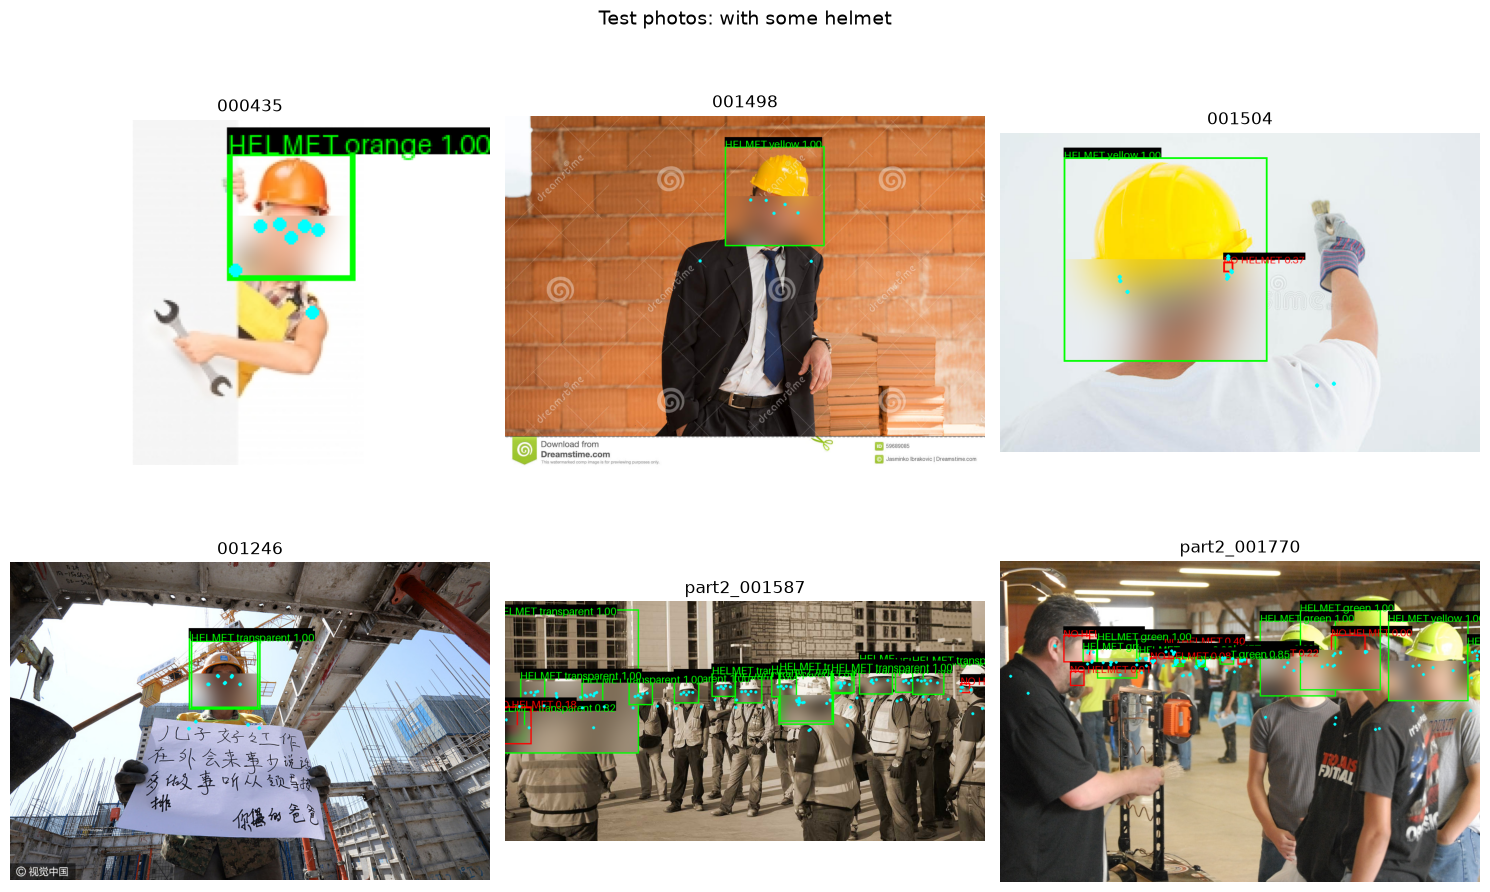

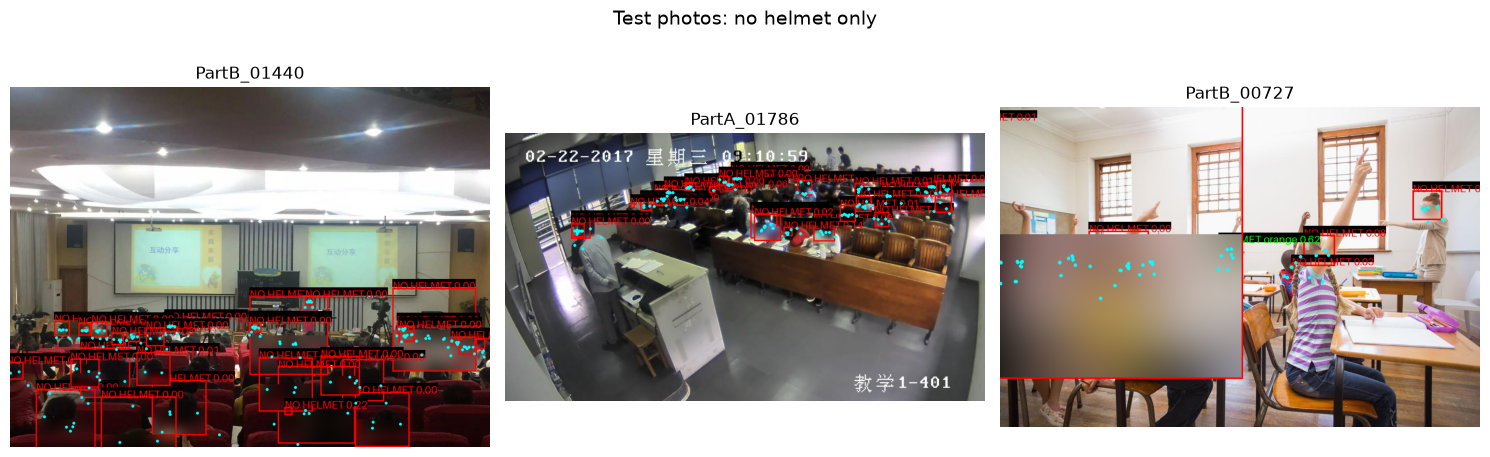

In [6]:
for kind, n, file in [("with some helmet", 6, "09_examples_helmet.png"), ("no helmet only", 3, "09_examples_no_helmet.png")]:
    examples = ev07[ev07.kind == kind].id.drop_duplicates().sample(n, random_state=1)
    fig, axes = plt.subplots(n // 3, 3, figsize=(15, 5 * n // 3), squeeze=False)
    for ax, img_id in zip(axes.ravel(), examples):
        img = ImageOps.exif_transpose(Image.open(SHWD / f"JPEGImages/{img_id}.jpg")).convert("RGB")
        res = analyze(img)
        out = draw(img, res); d = ImageDraw.Draw(out); w = max(3, img.width // 300)
        for _, r in res.iterrows():
            for (px, py), v in zip(r.kp[:7], r.vis[:7]):
                if v: d.ellipse((px - w, py - w, px + w, py + w), fill="cyan")
        ax.imshow(out); ax.set_title(img_id); ax.axis("off")
    fig.suptitle(f"Test photos: {kind}", fontsize=14)
    plt.tight_layout(); plt.savefig(OUTPUTS / file, dpi=100); plt.show()